# 04 - Route & product clustering
KMeans on route performance (avg lead, lead variability, distance, volume) to find consistently slow routes and congested region-product combinations.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # notebooks/<stage>/ -> project root
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src import config as C
from src import clustering

In [2]:
prepared = pd.read_csv(C.PROCESSED / 'orders_prepared.csv')
routes = clustering.cluster_routes(clustering.route_summary(prepared))
routes['Route Cluster'].value_counts()

Route Cluster
Low volume (<5 orders)    76
Fast                      59
Typical                   42
Slow                      19
Name: count, dtype: int64

In [3]:
routes[routes['Route Cluster']=='Slow'].sort_values('Avg_Lead', ascending=False).round(2)

,Origin Factory,State/Province,Orders,Units,Sales,Gross_Profit,Avg_Lead,Std_Lead,P90_Lead,Avg_Distance,Margin_Pct,Route,Route Cluster,Consistently Slow
9,Lot's O' Nuts,District of Columbia,8,35,126.00,85.30,5.38,0.92,6.0,1977.03,67.70,Lot's O' Nuts -> District of Columbia,Slow,True
19,Lot's O' Nuts,Maine,6,20,71.23,49.03,5.33,0.82,6.0,2404.50,68.83,Lot's O' Nuts -> Maine,Slow,True
140,Wicked Choccy's,Alberta,8,44,146.00,94.88,5.00,0.00,5.0,2128.72,64.99,Wicked Choccy's -> Alberta,Slow,True
183,Wicked Choccy's,Quebec,24,77,254.75,165.53,4.67,1.24,7.0,1043.49,64.98,Wicked Choccy's -> Quebec,Slow,True
43,Lot's O' Nuts,Prince Edward Island,6,22,78.10,54.90,4.67,0.52,5.0,2694.65,70.29,Lot's O' Nuts -> Prince Edward Island,Slow,True
47,Lot's O' Nuts,South Dakota,9,33,117.59,82.09,4.67,0.87,5.2,1010.40,69.81,Lot's O' Nuts -> South Dakota,Slow,True
1,Lot's O' Nuts,Alberta,16,57,204.32,141.42,4.62,0.50,5.0,1323.80,69.21,Lot's O' Nuts -> Alberta,Slow,True
172,Wicked Choccy's,New Mexico,17,68,229.50,149.26,4.53,1.01,5.4,1451.19,65.04,Wicked Choccy's -> New Mexico,Slow,True
4,Lot's O' Nuts,British Columbia,18,71,253.40,173.80,4.44,0.98,5.0,1291.68,68.59,Lot's O' Nuts -> British Columbia,Slow,True
27,Lot's O' Nuts,Montana,8,26,92.61,64.01,4.38,0.52,5.0,985.29,69.12,Lot's O' Nuts -> Montana,Slow,True


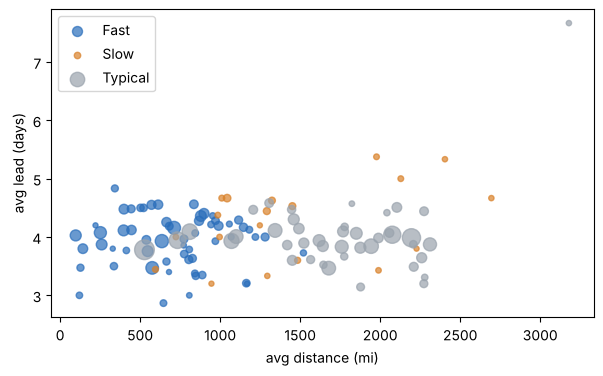

In [4]:
colors = {'Fast':'#2a6ebb','Typical':'#9aa3ad','Slow':'#d9822b'}
fig, ax = plt.subplots(figsize=(7,4))
for n, g in routes[routes['Route Cluster'].isin(colors)].groupby('Route Cluster'):
    ax.scatter(g['Avg_Distance'], g['Avg_Lead'], s=np.sqrt(g['Orders'])*6, alpha=.7, color=colors[n], label=n)
ax.set(xlabel='avg distance (mi)', ylabel='avg lead (days)'); ax.legend(); plt.show()

In [5]:
cong = clustering.congestion_table(prepared)
cong[cong['Congested']].round(2)

,Region,Product Name,Orders,Units,Avg_Lead,Std_Lead,Avg_Distance,Volume Rank,Lead Rank,Congested
0,Pacific,Wonka Bar - Milk Chocolate,666,2706,4.05,1.76,2116.65,0.94,0.88,True
1,Atlantic,Wonka Bar - Milk Chocolate,639,2336,4.05,1.74,741.81,0.91,0.84,True
2,Pacific,Wonka Bar - Fudge Mallows,569,2229,4.05,1.80,623.06,0.81,0.91,True
3,Interior,Wonka Bar - Milk Chocolate,499,1869,4.10,1.74,943.39,0.72,0.94,True


In [6]:
clustering.cluster_products(prepared).round(2)

,Product Name,Origin Factory,Division,Orders,Sales,Gross_Profit,Avg_Lead,Avg_Distance,Margin_Pct,Product Cluster
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,Chocolate,2137,26867.75,17443.37,4.05,1154.22,64.92,Core volume
1,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Chocolate,2064,27874.80,19357.50,3.92,1294.23,69.44,Core volume
2,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Chocolate,2015,28485.00,18610.20,3.98,1176.78,65.33,Core volume
3,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Chocolate,1818,24890.40,16593.60,3.96,1307.63,66.67,Core volume
4,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Chocolate,1810,23574.95,16819.95,3.92,1282.48,71.35,Core volume
5,Wonka Gum,Secret Factory,Other,120,597.50,310.70,3.70,815.86,52.00,Mid volume
6,Kazookles,The Other Factory,Other,96,1205.75,92.75,3.74,989.59,7.69,Mid volume
7,Lickable Wallpaper,Secret Factory,Other,94,7860.00,3930.00,3.71,900.42,50.00,Mid volume
8,Laffy Taffy,Sugar Shack,Sugar,10,53.73,33.48,4.20,1118.57,62.31,Long tail
9,SweeTARTS,Sugar Shack,Sugar,10,61.50,28.70,4.60,1091.15,46.67,Long tail


In [7]:
routes.to_csv(C.PROCESSED / 'route_clusters.csv', index=False)
cong.to_csv(C.PROCESSED / 'region_product_congestion.csv', index=False)
clustering.cluster_products(prepared).to_csv(C.PROCESSED / 'product_clusters.csv', index=False)